# Device selection

In [29]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.result import QuasiDistribution
from qiskit_aer import AerSimulator

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)
simulator = AerSimulator.from_backend(backend)

# Tests with small circuit

In [30]:
from qiskit.converters import circuit_to_dag
from qiskit import QuantumCircuit
from sympy import fwht, ifwht
from copy import deepcopy
import numpy as np

def empty_copy_circ(circ: QuantumCircuit):
    new_circ=deepcopy(circ)
    new_circ.data=[]
    return new_circ

def copy_node(new_qc, node):
    '''Applies the node to the circuit.'''
    # Copy the node.
    if node.name=="x":
        new_qc.x(node.qargs[0])
    elif node.name=="y":
        new_qc.y(node.qargs[0])
    elif node.name=="z":
        new_qc.z(node.qargs[0])
    elif node.name=="h":
        new_qc.h(node.qargs[0])
    elif node.name=="s":
        new_qc.s(node.qargs[0])
    elif node.name=="sdg":
        new_qc.sdg(node.qargs[0])
    elif node.name=="t":
        new_qc.t(node.qargs[0])
    elif node.name=="tdg":
        new_qc.tdg(node.qargs[0])
    elif node.name=="cx":
        new_qc.cx(node.qargs[0], node.qargs[1])
    elif node.name=="cz":
        new_qc.cz(node.qargs[0], node.qargs[1])
    elif node.name=="cs":
        new_qc.cs(node.qargs[0], node.qargs[1])
    elif node.name=="csdg":
        new_qc.csdg(node.qargs[0], node.qargs[1])
    elif node.name=="cp":
        new_qc.cp(node.op.params[0], node.qargs[0], node.qargs[1])
    elif node.name=="swap":
        new_qc.swap(node.qargs[0], node.qargs[1])
    elif node.name=="rx":
        new_qc.rx(node.op.params[0], node.qargs[0])
    elif node.name=="rz":
        new_qc.rz(node.op.params[0], node.qargs[0])
    elif node.name=="sx":
        new_qc.sx(node.qargs[0])
    elif node.name=="measure":
        # print(node.qargs[0]._index, node.op.params, type(node.cargs[0]))
        new_qc.measure(node.qargs[0], node.cargs)
    elif node.name=="id":
        new_qc.id(node.qargs[0])
    elif node.name=="reset":
        new_qc.reset(node.qargs[0])
    elif node.name=="if_else":
        # print(node.qargs)
        # print(node.cargs)
        # print(node.op.params)
        # assert False, "error"
        with new_qc.if_test((node.cargs[0], 1)):
            new_qc.z(node.qargs[0])
    elif node.name=="barrier":
        new_qc.barrier()   
        
    else:
        # We have overlooked a gate type.
        assert False, f"{node.name} gate wasn't matched in the DAG."

def replace_gates_h_sx_rx(circ: QuantumCircuit):
    '''Replaces h with y and sx with x.'''
    dag=circuit_to_dag(circ)
    new_qc=empty_copy_circ(circ)   

    op_nodes=dag.op_nodes()
    for node in op_nodes:
        # print(node.name)
        if node.name=="h":
            new_qc.y(node.qargs[0])
        elif node.name=="sx" or node.name=="rx":
            new_qc.x(node.qargs[0])
        else:
            copy_node(new_qc, node)
    return new_qc

def first_col_update_label(col_label, key):
    num_qubits=len(col_label)
    return bin(int(col_label, 2) ^ int(key, 2))[2:].zfill(num_qubits)

def convert_to_first_col(counts: dict, col_label: str):
    '''The label is the associated column of tilde A. Counts is the associated column values.
    We should convert these to the first column by the symmetry rule described in the paper.'''
    counts={first_col_update_label(col_label, key):value for (key, value) in counts.items()}
    return counts

def filter_counts(counts, num_keep):
    '''Returns a dict with only the largest num_keep elements.'''
    list_counts=sorted(counts.items(), key=lambda x: -x[1])
    filtered_counts=list_counts[:num_keep:]
    return {k:v for (k,v) in filtered_counts}

def fill_counts_range(counts1: dict, counts2: dict, num_keep, num_qubits):
    '''We embed the counts into a power of 2 number of basis states by padding with zeros.
    Some things to note: This is necessary to match the keys for both dict. Also,
    since FWHT solvers only see a vector, when they pad they can do it in an
    unphysical fashion (e.g., 111 is in the distribution so no padding should occur after the 111.)
    args: num_keep: should be a power of 2. Both list should have the same keys for the
    inverse Fourier transforms to generate correct results.'''
    counts1_keys=set(counts1.keys())
    counts2_keys=set(counts2.keys())
    new_counts1={}
    new_counts2={}
    exist_keys=list(counts1_keys.union(counts2_keys))
    exist_keys=[int(elem, 2) for elem in exist_keys]
    exist_keys=sorted(exist_keys)
    # print("max exist ", max(exist_keys))
    # print("min exist ", min(exist_keys))
    # print("size before ", len(exist_keys))
    max_key=exist_keys[-1]
    min_key=exist_keys[0]
    current_len=len(exist_keys)
    if num_keep>=max_key:
        max_key=num_keep
        all_keys=list(range(num_keep))
    else: #num_keep<max_key. we will pad between until the size is right
        if num_keep<current_len: #the current len exceeds what was kept.
            # go to the nearest larger power of 2.
            power=int(np.ceil(np.log2(current_len)))
            max_key=num_keep=2**power
        all_possible_between=iter(range(min_key, max_key))
        all_possible_before=iter(range(0, min_key))
        new_keys_between=[]
        new_keys_before=[]
        # we should pad with elements between the min and max keys before outside.
        while len(new_keys_between)<num_keep-current_len:
            try:
                next_elem=next(all_possible_between)
                while next_elem in exist_keys:
                    try:
                        next_elem=next(all_possible_between)
                    except StopIteration:
                        raise StopIteration
            except StopIteration:
                break
            new_keys_between.append(next_elem)
        while len(new_keys_between)+len(new_keys_before)+len(exist_keys)<num_keep:
            # pad with before elements
            next_elem=next(all_possible_before)
            new_keys_before.append(next_elem)

        all_keys=exist_keys+new_keys_between+new_keys_before
        
    all_keys=[bin(elem)[2::].zfill(num_qubits) for elem in all_keys]

    for k in all_keys:
        new_counts1[k]=counts1.get(k,0)
        new_counts2[k]=counts2.get(k,0)
    assert len(all_keys)==len(new_counts1)
    assert len(all_keys)==len(new_counts2)

    return sorted(list(all_keys), key=lambda x: int(x)), new_counts1, new_counts2

def filled_dict_to_vec(filled_samples_dict):
    if not float(np.log2(len(filled_samples_dict))).is_integer():
        raise ValueError("The number of keys in the samples dict must be a power of 2.")
    sorted_distribution = sorted(list(filled_samples_dict.items()), key=lambda x: int(x[0], 2))
    return np.array([el[1] for el in sorted_distribution])

def get_quasi_corrected(noisy_noise_est_vec, counts_vec):
    '''Solves the circulant structure system with FWHT.'''
    fft_calmat_col=np.array(fwht(noisy_noise_est_vec), dtype=float)
    fft_noisy_counts=np.array(fwht(counts_vec), dtype=float)
    # print(len(fft_calmat_col))
    # print(len(fft_noisy_counts))
    quasi_corrected_counts=ifwht(np.divide(fft_noisy_counts, fft_calmat_col, out=np.zeros(len(fft_noisy_counts)), where=(fft_calmat_col!=0)))
    return np.array(quasi_corrected_counts, dtype=float)[0:len(noisy_noise_est_vec)]

def dec_mitigation(payload_noisy_samples, calibration_noisy_samples, calibration_ideal_samples, num_keep=2**20):
    if len(calibration_ideal_samples) != 1:
        raise ValueError("Calibration samples must only contain samples from a single basis state.")
    if sum(payload_noisy_samples.values()) != sum(calibration_noisy_samples.values()) != sum(calibration_ideal_samples.values()):
        raise ValueError("All samples dicts must contain the same number of shots.")
    shots = sum(payload_noisy_samples.values())
    calibration_column_label = list(calibration_ideal_samples.keys())[0]
    nqubits = len(calibration_column_label)

    # Generate the distribution vectors with correct ordering and length
    payload_noisy_samples = convert_to_first_col(payload_noisy_samples, calibration_column_label)
    payload_noisy_samples = filter_counts(payload_noisy_samples, num_keep)
    calibration_noisy_samples = filter_counts(calibration_noisy_samples, num_keep)
    final_labels, filled_payload_noisy_samples, filled_calibration_noisy_samples,  = fill_counts_range(payload_noisy_samples, calibration_noisy_samples, min(2**nqubits, num_keep), nqubits)
    filled_payload_samples_vec = filled_dict_to_vec(filled_payload_noisy_samples)
    filled_calibration_samples_vec = filled_dict_to_vec(filled_calibration_noisy_samples)

    # Get the corrected payload distribution
    payload_quasi_corrected_dist_vec = get_quasi_corrected(filled_calibration_samples_vec, filled_payload_samples_vec)
    payload_quasi_dist_dict = {label:prob for label, prob in zip(final_labels, payload_quasi_corrected_dist_vec)}
    payload_quasi_dist = QuasiDistribution(payload_quasi_dist_dict)
    payload_dist_dict = payload_quasi_dist.nearest_probability_distribution().binary_probabilities(nqubits)

    return payload_dist_dict

In [31]:
from qiskit import QuantumCircuit, generate_preset_pass_manager

n = 10

qc = QuantumCircuit(n)
qc.h(0)
for i in range(n-1):
    qc.cx(i, i + 1)
qc.measure_all()

pm = generate_preset_pass_manager(backend=simulator, optimization_level=3)
tqc = pm.run(qc)

testc = replace_gates_h_sx_rx(tqc)

testc.draw(idle_wires=False)

global phase: 3π/4
          ┌─────────┐┌───┐ ┌───────┐                                          »
 q_5 -> 3 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
          ├─────────┤├───┤ ├───────┤                                          »
 q_4 -> 4 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
          ├─────────┤├───┤ ├───────┤                                          »
 q_3 -> 5 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├────────────────────────────────────────■─»
          ├─────────┤├───┤ ├───────┤                       ┌───┐┌─────────┐ │ »
 q_2 -> 6 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├─────────────────────■─┤ X ├┤ Rz(π/2) ├─■─»
          ├─────────┤├───┤ ├───────┤    ┌───┐┌─────────┐ │ └───┘└─────────┘   »
 q_1 -> 7 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──■─┤ X ├┤ Rz(π/2) ├─■────────────────────»
          ├─────────┤├───┤┌┴───────┴┐ │ └───┘└─────────┘                      »
 q_0 -> 8 ┤ Rz(π/2) ├┤ X ├┤ Rz(π/2) ├─■───────────────────────────────────────»
          ├─────────┤├───┤└┬───────┬┘                                         »
q_6 -> 16 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
          ├─────────┤├───┤ ├───────┤                                          »
q_9 -> 21 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
          ├─────────┤├───┤ ├───────┤                                          »
q_8 -> 22 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
          ├─────────┤├───┤ ├───────┤                                          »
q_7 -> 23 ┤ Rz(π/2) ├┤ X ├─┤ Rz(π) ├──────────────────────────────────────────»
          └─────────┘└───┘ └───────┘                                          »
 meas: 10/════════════════════════════════════════════════════════════════════»
                                                                              »
«                                                ┌───┐┌─────────┐        »
« q_5 -> 3 ────────────────────────────────────■─┤ X ├┤ Rz(π/2) ├─■──────»
«                             ┌───┐┌─────────┐ │ └───┘└─────────┘ │      »
« q_4 -> 4 ─────────────────■─┤ X ├┤ Rz(π/2) ├─■──────────────────┼──────»
«          ┌───┐┌─────────┐ │ └───┘└─────────┘                    │      »
« q_3 -> 5 ┤ X ├┤ Rz(π/2) ├─■─────────────────────────────────────┼──────»
«          └───┘└─────────┘                                       │      »
« q_2 -> 6 ───────────────────────────────────────────────────────┼──────»
«                                                                 │      »
« q_1 -> 7 ───────────────────────────────────────────────────────┼──────»
«                                                                 │      »
« q_0 -> 8 ───────────────────────────────────────────────────────┼──────»
«                                                                 │ ┌───┐»
«q_6 -> 16 ───────────────────────────────────────────────────────■─┤ X ├»
«                                                                   └───┘»
«q_9 -> 21 ──────────────────────────────────────────────────────────────»
«                                                                        »
«q_8 -> 22 ──────────────────────────────────────────────────────────────»
«                                                                        »
«q_7 -> 23 ──────────────────────────────────────────────────────────────»
«                                                                        »
« meas: 10/══════════════════════════════════════════════════════════════»
«                                                                        »
«                                                                              »
« q_5 -> 3 ────────────────────────────────────────────────────────────────────»
«                                                                              »
« q_4 -> 4 ────────────────────────────────────────────────────────────────────»
«                                                                              »
« q_3 -> 5 

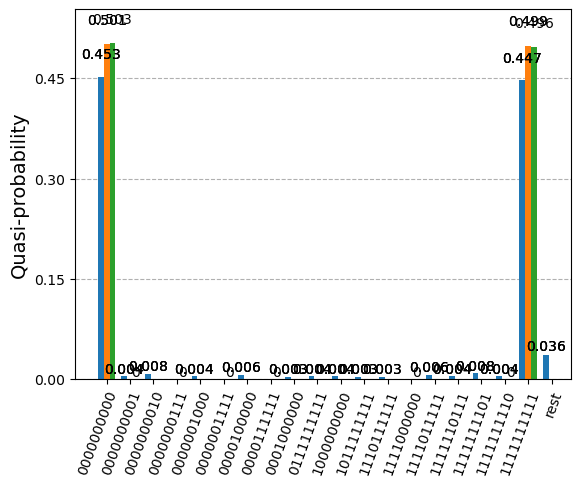

In [32]:
from qiskit.visualization import plot_histogram

ideal_simulator = AerSimulator(method="stabilizer")

noisy_samples_dicts = simulator.run(tqc, shots=100000).result().get_counts()
ideal_samples_dicts = ideal_simulator.run(tqc, shots=100000).result().get_counts()
test_noisy_samples_dicts = simulator.run(testc, shots=100000).result().get_counts()
test_ideal_samples_dicts = ideal_simulator.run(testc, shots=100000).result().get_counts()

corrected_samples_dicts = dec_mitigation(noisy_samples_dicts, test_noisy_samples_dicts, test_ideal_samples_dicts)

# plot_histogram([test_noisy_samples_dicts, test_ideal_samples_dicts], number_to_keep=15)
plot_histogram([noisy_samples_dicts, ideal_samples_dicts, corrected_samples_dicts], number_to_keep=15)

In [33]:
corrected_samples_dicts

{'0000111111': 4.1863746227748704e-05,
 '1111000000': 4.2126771708946064e-05,
 '1111111110': 0.00019218160282057474,
 '0000001111': 0.00019809628755776084,
 '0000000001': 0.00023146951009789642,
 '0000000111': 0.000258851713671469,
 '1111111111': 0.49639391504508656,
 '0000000000': 0.502641495322829}

# Simulation settings

In [34]:
from z2chain.gdd import zero_mean
from functools import partial
import numpy as np

L = 5
J = 2
h = 0.8
lamb = 1

x_basis = False

fractional_gates = False

particle_position = 2

final_time = 8
dt = 0.125
steps = 40
desired_error = 1e-2

shots = 75000
confidence = 0.7

dec = True
flip_threshold = 1
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean
# g_func = None

# Trotter truth

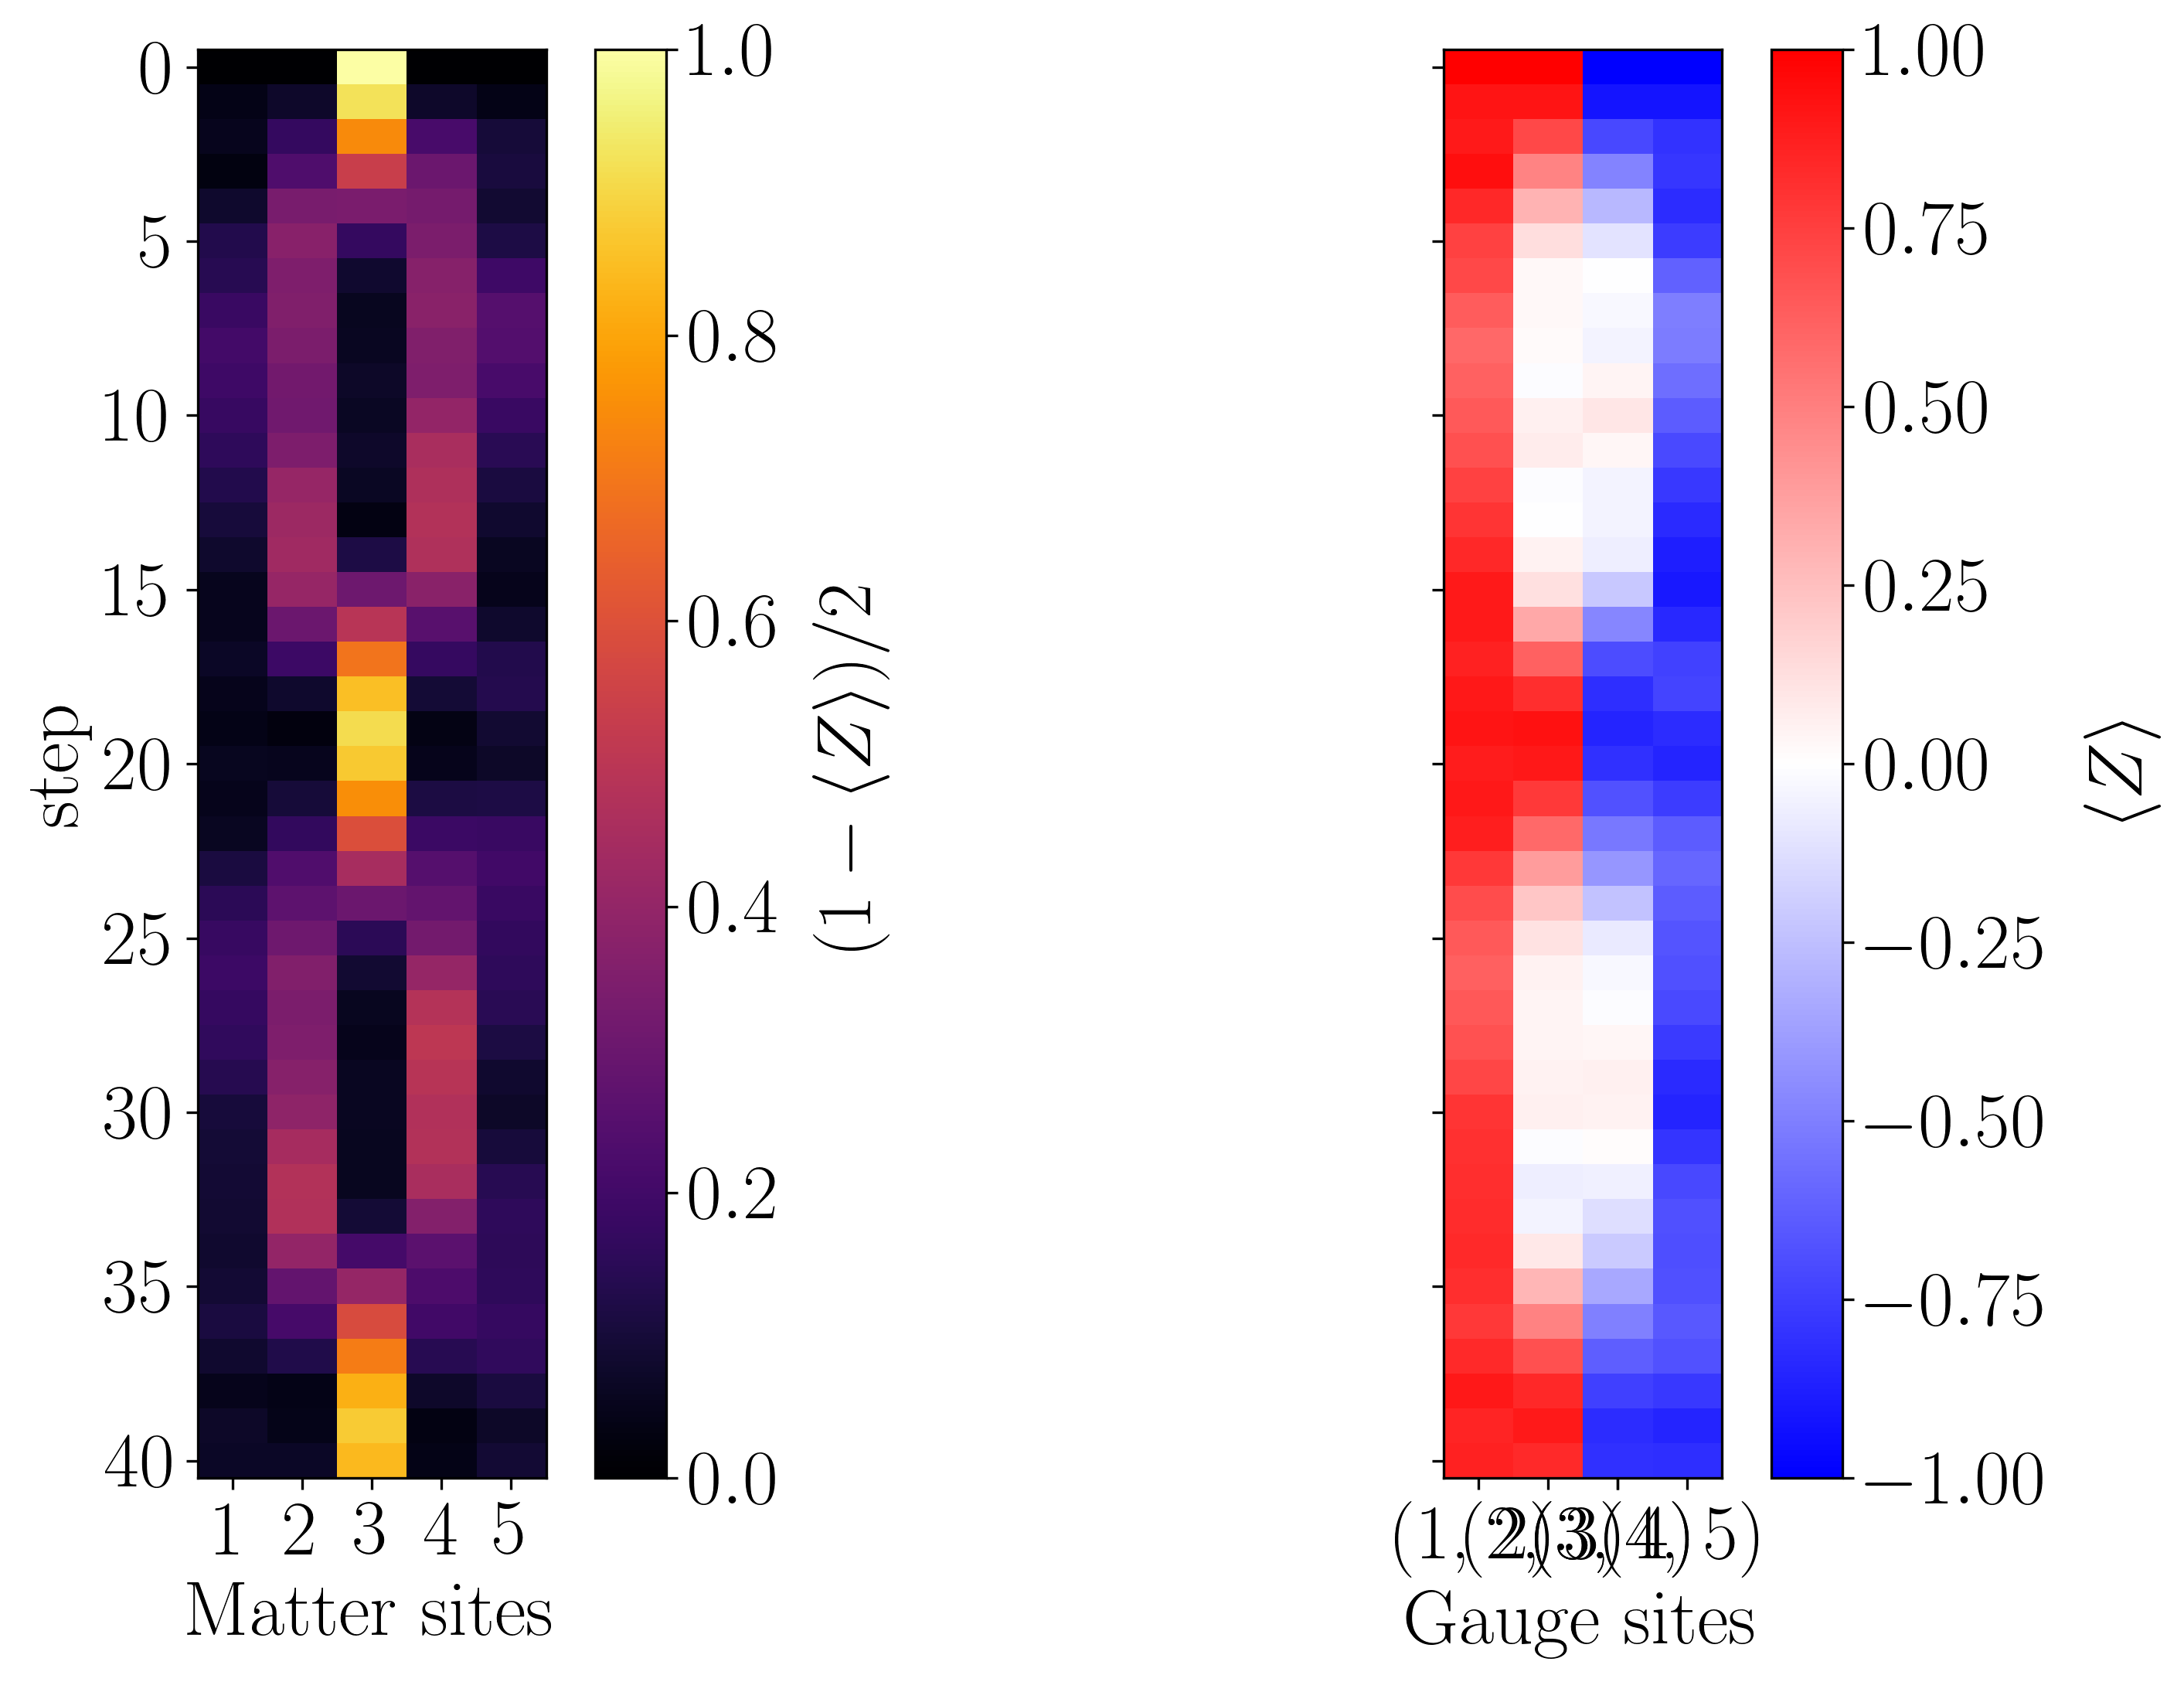

In [35]:
from z2chain.plotting import x_t_separated_plot
import z2chain.exact as exact

exact_observables = exact.singlep_quench_trotter2_simulation(L, J, h, lamb, particle_position, final_time/steps, steps)

x_t_separated_plot(exact_observables)

# Circuit transpilation

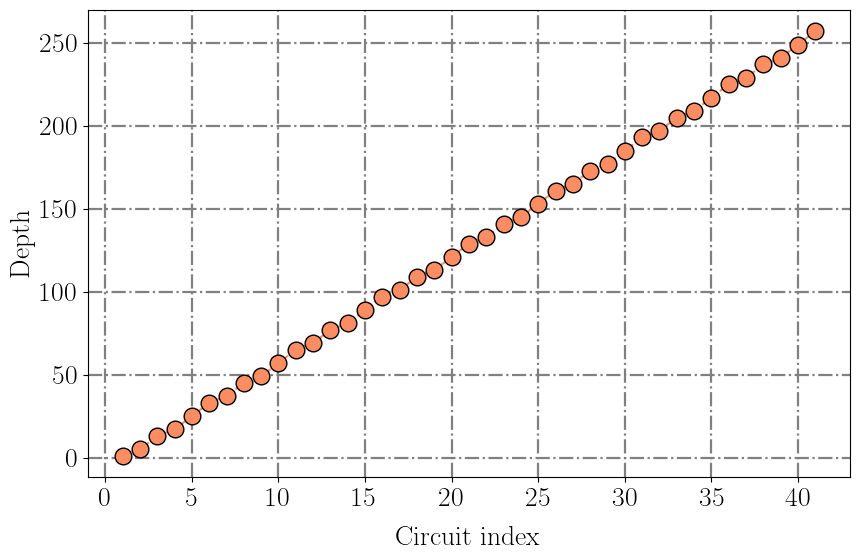

In [36]:
from z2chain.circs import singlep_quench_odr_compuncomp_circuits_dt, singlep_quench_simulation_and_odr_compuncomp_circs
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.hexec import get_backend_best_qubit_chain
from utils.plotting import plot_circuit_arr_depth
import numpy as np
import os

optimization_level = 3
layout = get_backend_best_qubit_chain(backend, 2*L-1)
circs_args = (L, J, h, lamb, particle_position, final_time, dt, steps, backend, optimization_level, g_func, layout, x_basis, False)
if dec:
    circuits, odr_circuits = singlep_quench_simulation_and_odr_compuncomp_circs(*circs_args)
else:
    circuits = singlep_quench_simulation_and_odr_compuncomp_circs(*circs_args)
observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)

plot_circuit_arr_depth(circuits)

In [37]:
import numpy as np

print("\rRunning simulation...".ljust(100), end="")
samples_dicts = []
if dec: dec_samples_dicts = []
for i in range(len(circuits)):
    print(f"\ri = {i}".ljust(100), end="")
    this_samples_dict = simulator.run(circuits[i], shots=shots).result().get_counts()
    samples_dicts.append(this_samples_dict)
    if dec:
        this_odr_samples_dict = simulator.run(odr_circuits[i], shots=shots).result().get_counts()
        dec_samples_dicts.append(this_odr_samples_dict)
samples_dicts = np.array(samples_dicts)
if dec: dec_samples_dicts = np.array(dec_samples_dicts)
ideal_samples_dicts = {"0"*(2*L-1):shots}

i = 40                                                                                             

## ODR (Previous treatment)

In [38]:
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, compute_depolarizing_probability, pauli_to_str
from qiskit.quantum_info import PauliList, Pauli
from utils.odr import renormalize_observable

odr = True

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
to_remove_str = "I"*(2*L-3) + "ZZ"
to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
flipped_syndromes[to_remove_str_ind] = 1

postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
if odr:
    postselected_odr_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(dec_samples_dicts, postselection_ops, flip_threshold, recovery_function=None)

sim_observables, sim_observables_confidence = multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
raw_observables, raw_observables_confidence = multiprocess_measure_diagonal_observables(samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
if odr:
    odr_observables, odr_observables_confidence = multiprocess_measure_diagonal_observables(postselected_odr_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
    clean_odr_observables = np.zeros_like(sim_observables)
    clean_odr_observables_confidence = np.zeros_like(sim_observables_confidence)
    for i in range(len(sim_observables)):
        p_arr = compute_depolarizing_probability(odr_observables[i], 1, 0, odr_circuits[1].num_qubits)
        clean_odr_observables[i], clean_odr_observables_confidence[i] = renormalize_observable(sim_observables[i], p_arr, 0, circuits[1].num_qubits, observable_range=(-1, 1), expected_observable_arr=1, observable_confidence=sim_observables_confidence[i])

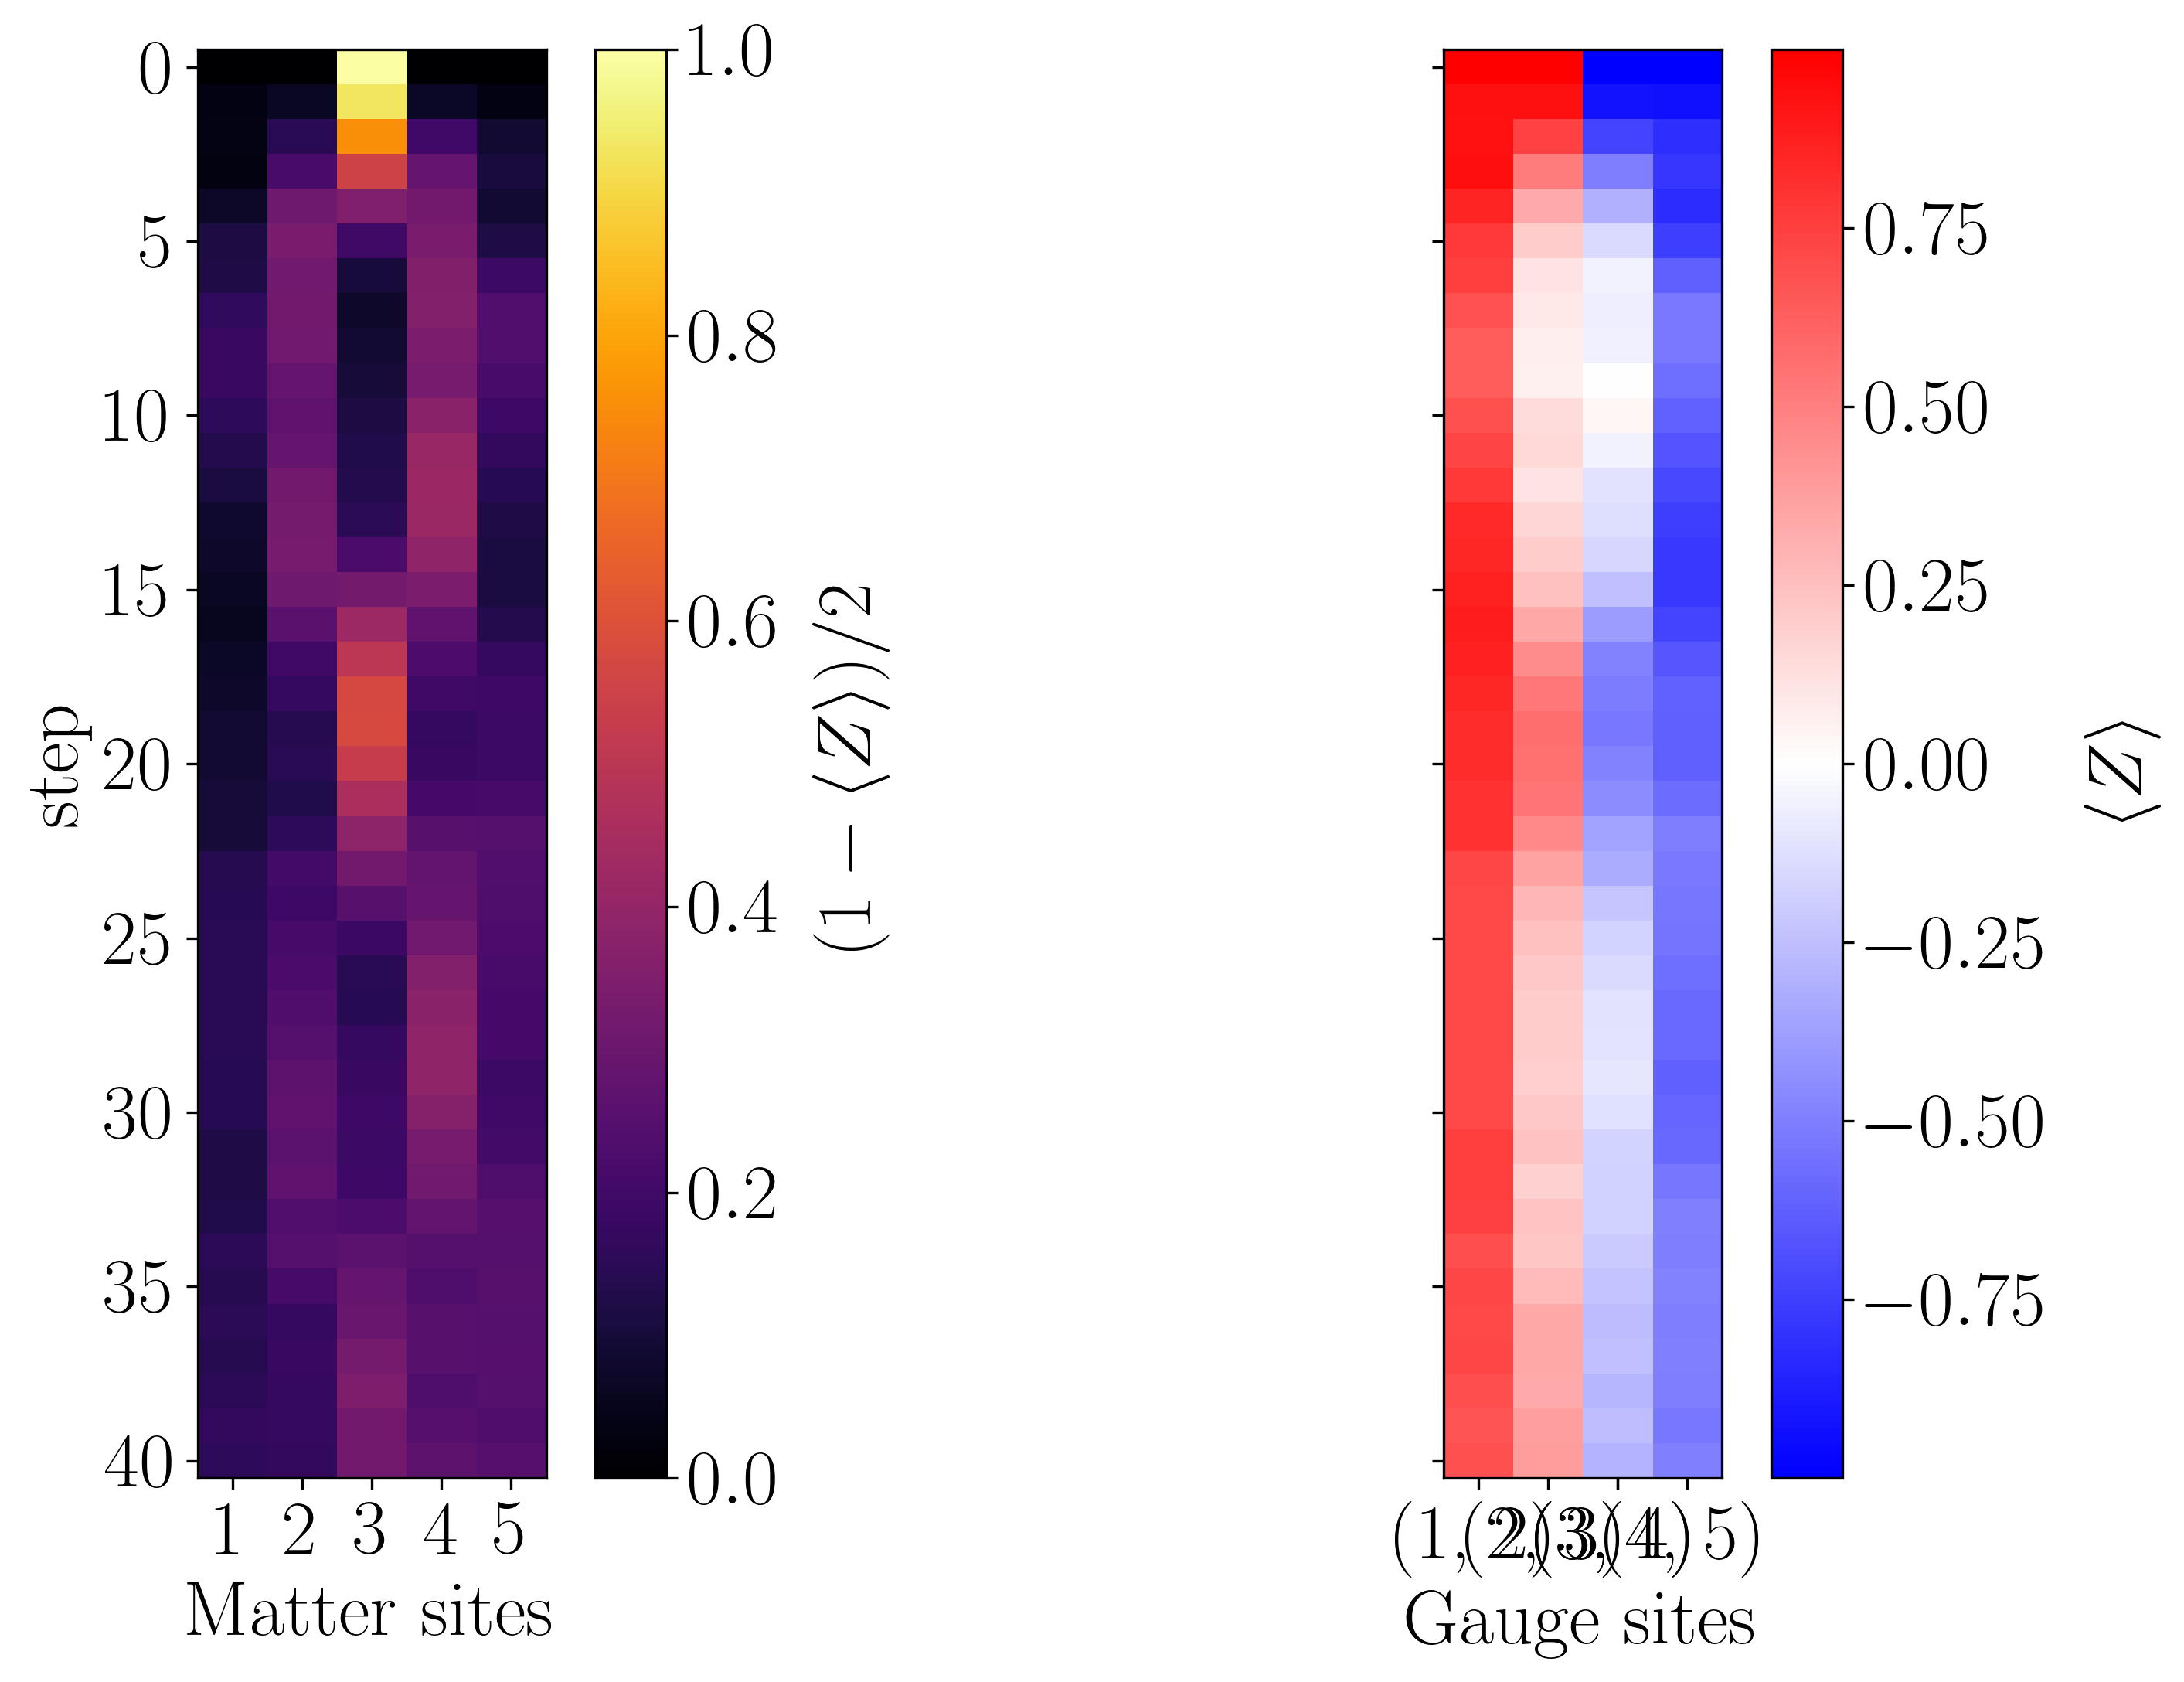

In [39]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(clean_odr_observables, cbar_range_matter=[0, 1])

## DEC (New approach)

In [42]:
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, compute_depolarizing_probability, pauli_to_str
from utils.odr import renormalize_observable
import numpy as np

corrected_samples_dicts = np.zeros_like(samples_dicts)

for i in range(len(samples_dicts)):
    corrected_samples_dicts[i] = dec_mitigation(samples_dicts[i], dec_samples_dicts[i], ideal_samples_dicts)

print("\rMeasuring observables...".ljust(100), end="")
postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
to_remove_str = "I"*(2*L-3) + "ZZ"
to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
flipped_syndromes[to_remove_str_ind] = 1

postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
postselected_samples_dicts.reshape(samples_dicts.shape)
postselected_dec_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(dec_samples_dicts, postselection_ops, flip_threshold, recovery_function=None)
postselected_dec_samples_dicts.reshape(dec_samples_dicts.shape)

corrected_samples_dicts = np.zeros_like(samples_dicts)

for i in range(len(samples_dicts)):
    corrected_samples_dicts[i] = dec_mitigation(samples_dicts[i], dec_samples_dicts[i], ideal_samples_dicts)

corrected_observables = multiprocess_measure_diagonal_observables(corrected_samples_dicts, diagonal_observables)
corrected_postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(corrected_samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
corrected_postselected_observables = multiprocess_measure_diagonal_observables(corrected_postselected_samples_dicts, diagonal_observables)

Measuring observables...                                                                           

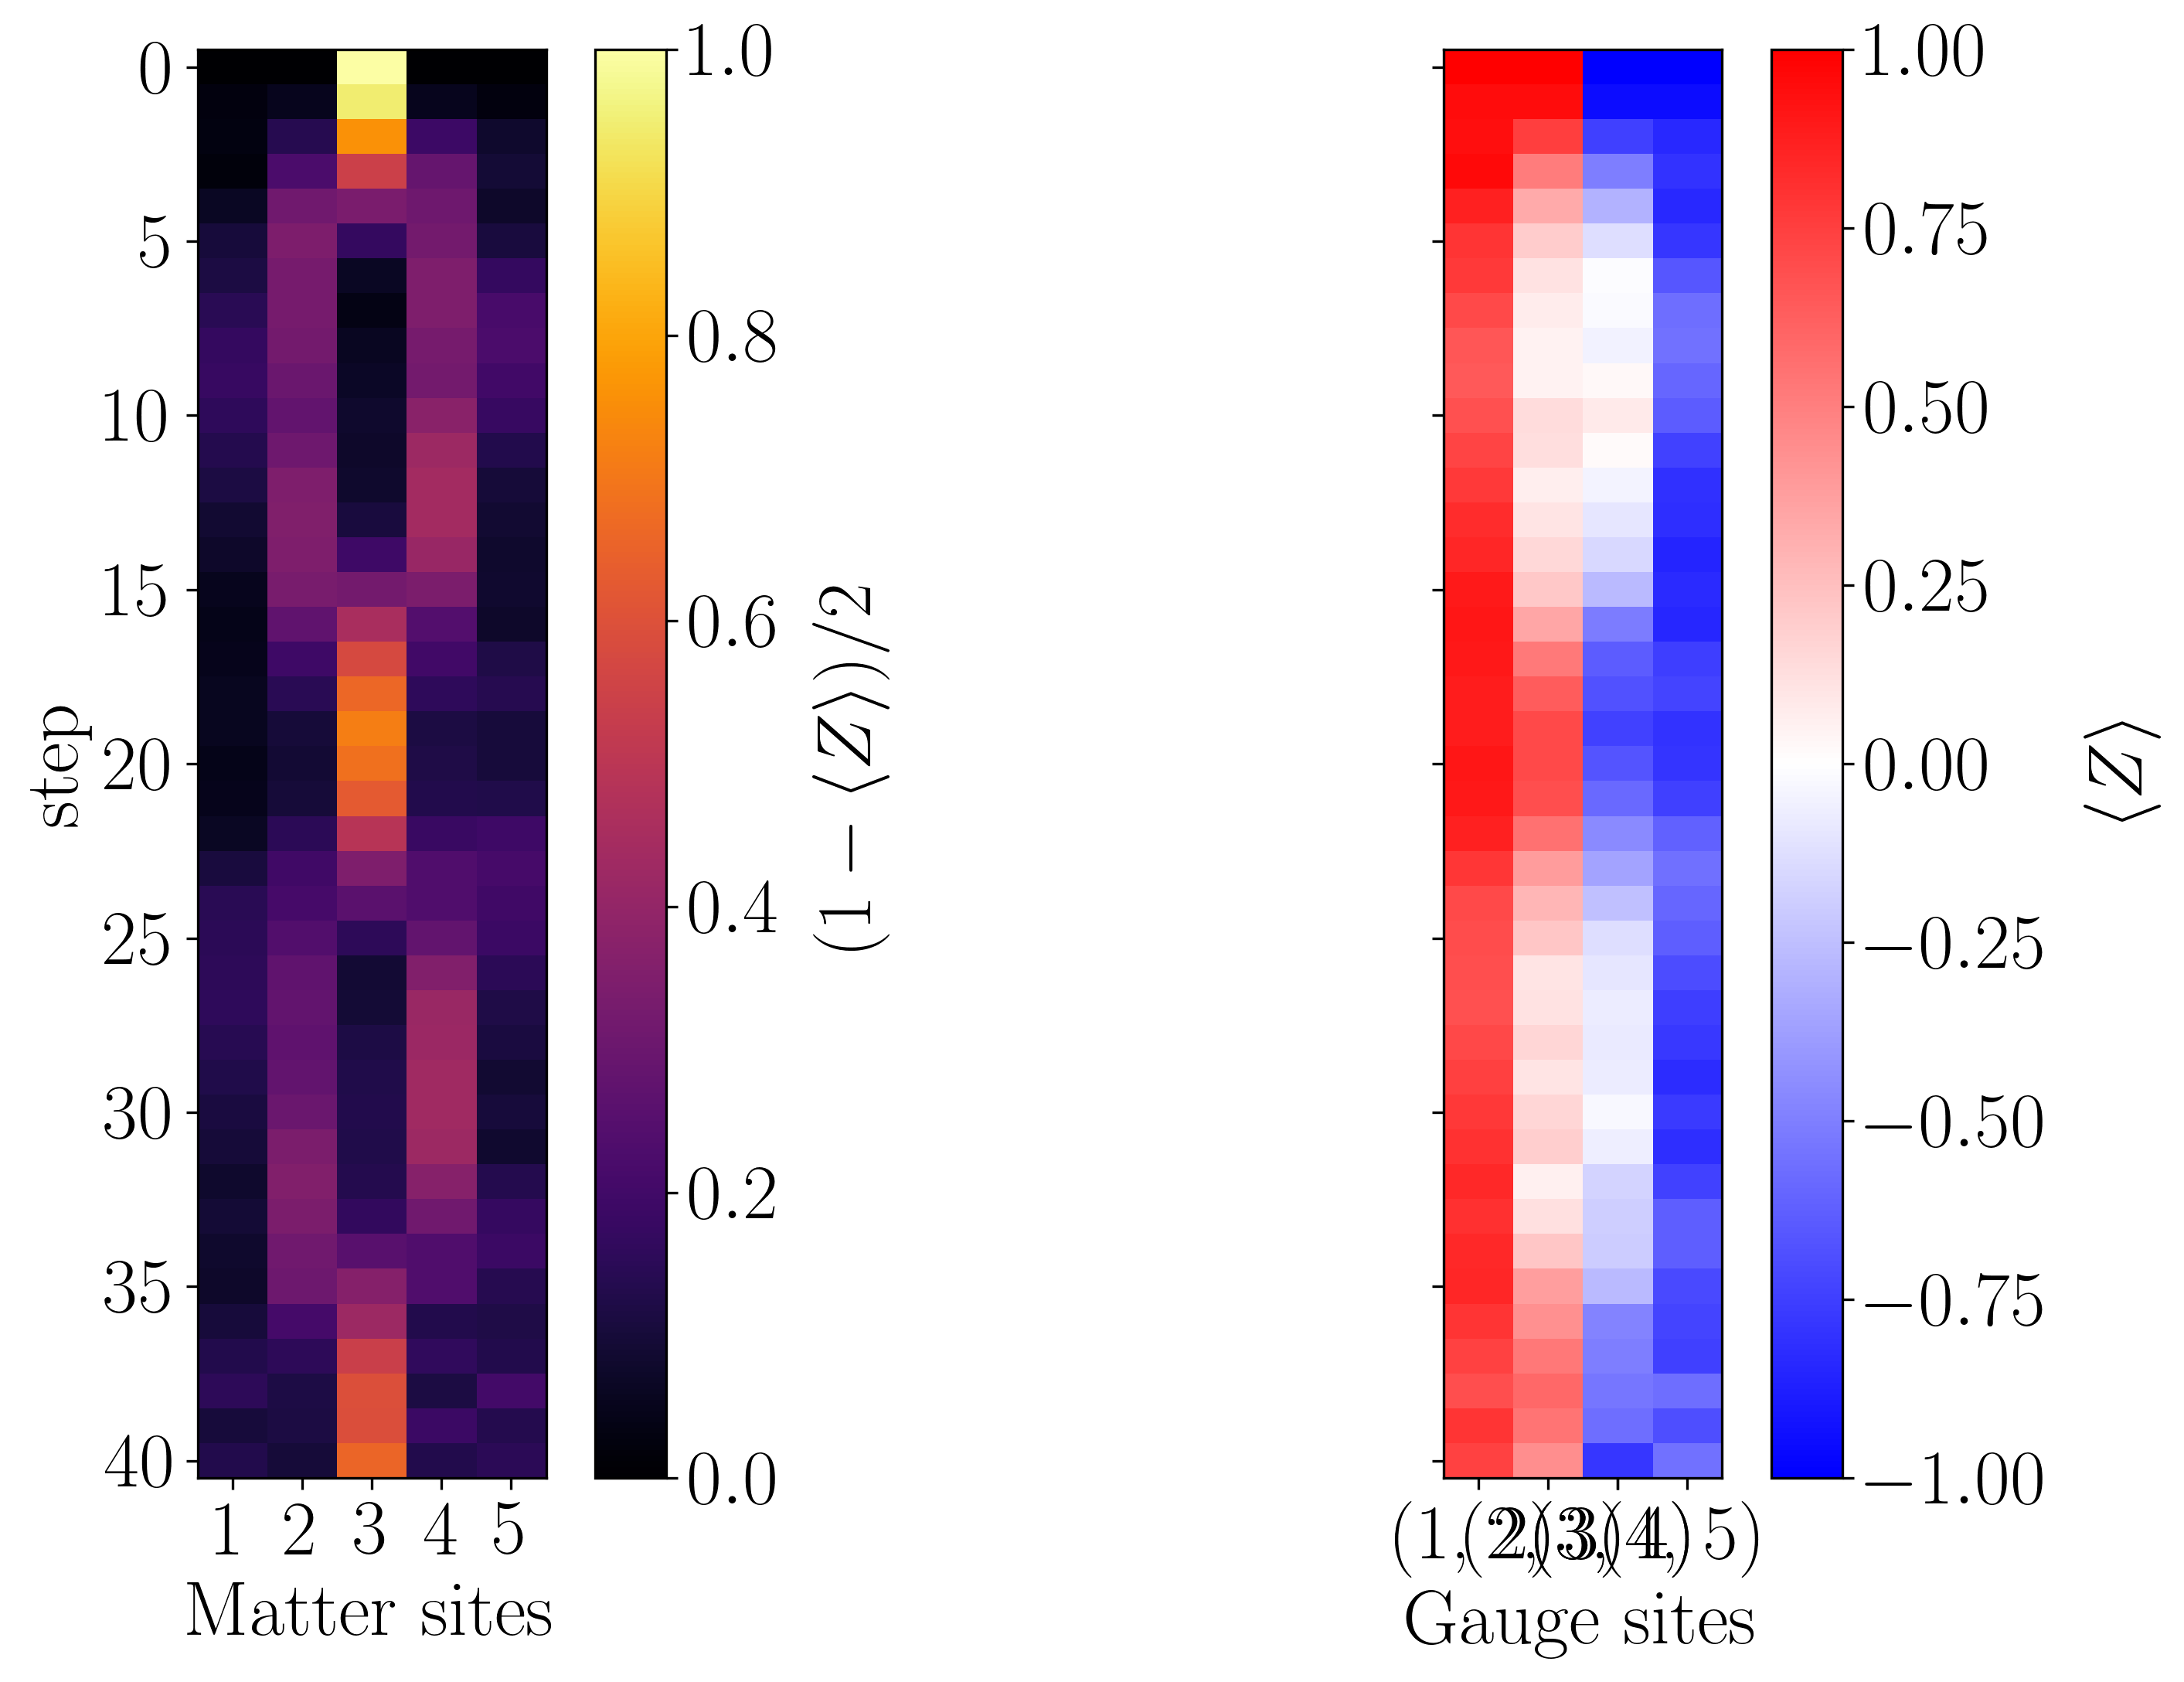

In [43]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(corrected_observables, cbar_range_matter=[0, 1])

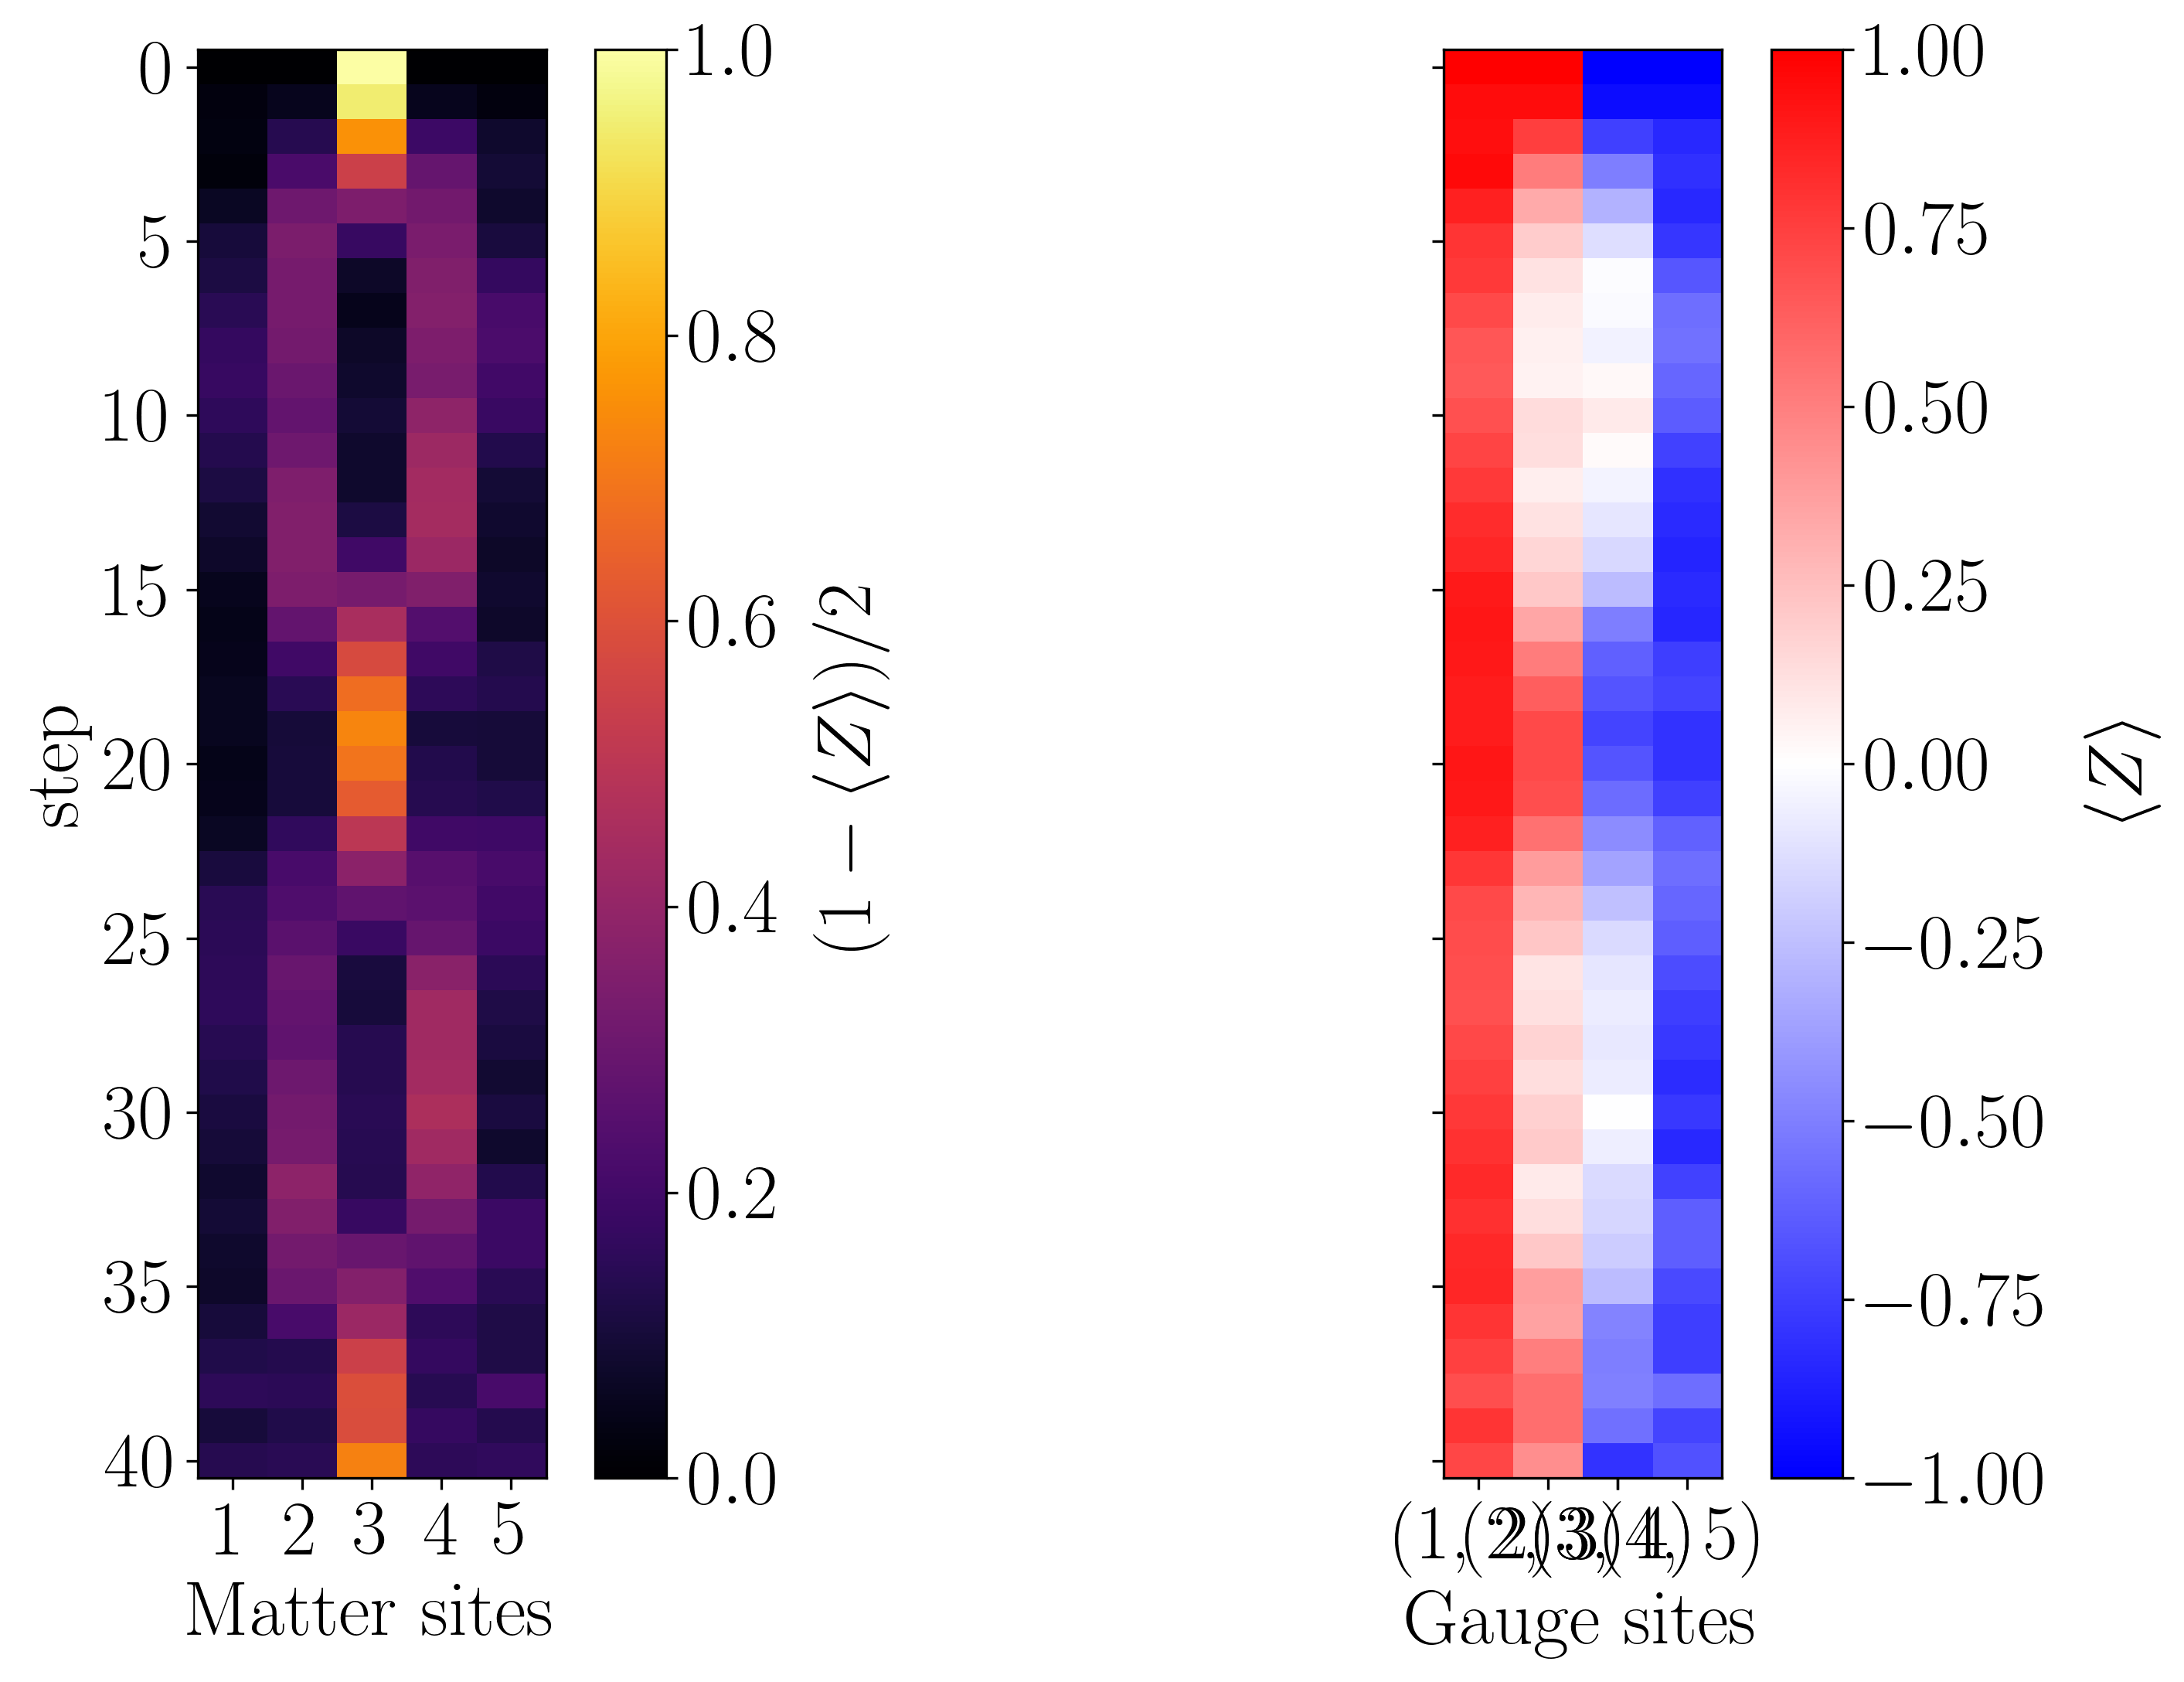

In [44]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(corrected_postselected_observables, cbar_range_matter=[0, 1])

## Comparison among approaches

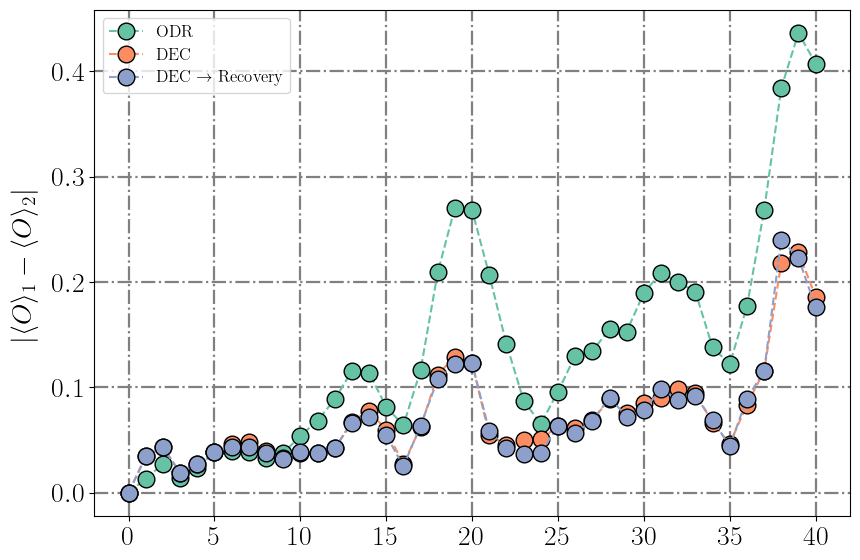

In [45]:
from utils.plotting import plot_mean_deviations

observables_matrices = [clean_odr_observables, corrected_observables, corrected_postselected_observables]
labels=[r"ODR", r"DEC", r"DEC $\rightarrow$ Recovery"]

plot_mean_deviations(observables_matrices, [exact_observables]*len(observables_matrices), labels=labels)